# Desafío Tiendas Super Niño — Logística

**Analítica de Datos · Negocios Digitales · UdeSA**

## El caso
Super Niño despacha cada pedido con un courier estándar. Algunos llegan tarde y cada atraso cuesta plata (reembolso del envío, cupón de disculpa, atención del reclamo). El courier premium garantiza la fecha, pero es más caro y el contrato solo permite usarlo en pocos pedidos por lote.

**Pregunta a responder:** ¿A qué pedidos del lote les asignamos el courier premium para minimizar el costo total?

**Datos disponibles:** `historico.csv` (con resultado) y `casos_nuevos.csv` (sin resultado, es lo que hay que decidir hoy).

**Variable a predecir:** `atrasado` (en el archivo original, `late_flag`)

**Restricción clave:** 25 pedidos por lote con premium. El premium cuesta $2.700 más que el estándar; un atraso cuesta $9.000.

**Qué se optimiza:** plata ahorrada en el lote = 6.300 × (premium que se iban a atrasar) − 2.700 × (premium que llegaban en fecha igual), con un techo de 25 premium.

> Recordatorio: gana el equipo que toma la mejor decisión de negocio, no el que escribe más código. Cada decisión de este notebook tiene que poder explicarse en voz alta.

| Stream | Secciones |
|---|---|
| A. EDA | 1 y 2 (ya armadas: hay que interpretarlas) |
| B. Modelado | 3, 4 y 5 |
| C. Comunicación | 6 y 7 |

## 0. Setup

Librerías, semilla y los números del metadata (costos y cupo) en un solo lugar, para no tener que volver a buscarlos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import roc_auc_score

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

# Datos del metadata
COSTO_ATRASO = 9000      # costo promedio de un pedido atrasado
COSTO_PREMIUM = 2700     # sobrecosto del courier premium sobre el estandar, por pedido
CUPO = 25                # pedidos premium por lote

In [2]:
def pesos(x):
    return "$" + f"{x:,.0f}".replace(",", ".")


def tabla_tasa(df, col, objetivo):
    return df.groupby(col, observed=True, dropna=False)[objetivo].agg(tasa="mean", n="count")


def grafico_tasa(df, col, objetivo, ax):
    tabla = tabla_tasa(df, col, objetivo)
    etiquetas = []
    for valor in tabla.index:
        if pd.isna(valor):
            etiquetas.append("sin dato")
        else:
            etiquetas.append(str(valor))
    ax.bar(etiquetas, tabla["tasa"] * 100, color="#4C72B0")
    ax.axhline(df[objetivo].mean() * 100, color="red", linestyle="--", label="promedio general")
    for i in range(len(tabla)):
        ax.text(i, tabla["tasa"].iloc[i] * 100 + 1, f"n={tabla['n'].iloc[i]}", ha="center", fontsize=8)
    ax.set_title(col)
    ax.set_ylabel(f"% con {objetivo}")
    ax.set_ylim(0, 105)
    ax.tick_params(axis="x", labelrotation=30)
    ax.legend()


def grilla_tasas(df, columnas, objetivo, ancho=5):
    fig, axes = plt.subplots(1, len(columnas), figsize=(ancho * len(columnas), 4), squeeze=False)
    for ax, col in zip(axes[0], columnas):
        grafico_tasa(df, col, objetivo, ax)
    plt.tight_layout()
    plt.show()


def mapa_tasa(df, fila, columna, objetivo, ax, n_min=5):
    tasa = df.pivot_table(index=fila, columns=columna, values=objetivo, aggfunc="mean", observed=True) * 100
    n = df.pivot_table(index=fila, columns=columna, values=objetivo, aggfunc="count", observed=True)
    # celdas con pocos casos: sin color (0) pero con su n anotado; celdas sin casos: vacías
    tasa_vista = tasa.where(n >= n_min, 0).where(n.notna())
    etiquetas = np.full(tasa.shape, "", dtype=object)
    for i in range(tasa.shape[0]):
        for j in range(tasa.shape[1]):
            cantidad = n.iloc[i, j]
            if np.isnan(cantidad):
                continue
            if cantidad < n_min:
                etiquetas[i, j] = f"n={int(cantidad)}"
            else:
                etiquetas[i, j] = f"{tasa.iloc[i, j]:.0f}%\n(n={int(cantidad)})"
    sns.heatmap(tasa_vista, annot=etiquetas, fmt="", cmap="Reds", vmin=0, vmax=100,
                cbar_kws={"label": f"% con {objetivo}"}, ax=ax)
    ax.grid(False)
    ax.set_title(f"{fila} x {columna}")


def intervalo_wilson(exitos, n, z=1.96):
    p = exitos / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - margen, centro + margen


def grafico_intervalos(df, col, objetivo, ax):
    grupos = df.groupby(col, observed=True)[objetivo].agg(["sum", "count"])
    for i in range(len(grupos)):
        inferior, superior = intervalo_wilson(grupos["sum"].iloc[i], grupos["count"].iloc[i])
        tasa = grupos["sum"].iloc[i] / grupos["count"].iloc[i]
        ax.plot([inferior * 100, superior * 100], [i, i], color="#4C72B0", linewidth=2)
        ax.plot(tasa * 100, i, "o", color="#4C72B0")
    ax.axvline(df[objetivo].mean() * 100, color="red", linestyle="--", label="promedio general")
    ax.set_yticks(range(len(grupos)))
    ax.set_yticklabels([str(valor) for valor in grupos.index])
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("% (con intervalo de confianza del 95%)")
    ax.set_title(col)
    ax.legend()


def grilla_intervalos(df, columnas, objetivo, ncols=2, alto=3.6):
    filas = int(np.ceil(len(columnas) / ncols))
    fig, axes = plt.subplots(filas, ncols, figsize=(6 * ncols, alto * filas), squeeze=False)
    for ax, col in zip(axes.ravel(), columnas):
        grafico_intervalos(df, col, objetivo, ax)
    plt.tight_layout()
    plt.show()


def curva_riesgo(df, col, objetivo, ax, grupos=8):
    datos = df[[col, objetivo]].dropna().copy()
    datos["tramo"] = pd.qcut(datos[col], grupos, duplicates="drop")
    resumen = datos.groupby("tramo", observed=True).agg(x=(col, "median"), exitos=(objetivo, "sum"), n=(objetivo, "count"))
    tasas = (resumen["exitos"] / resumen["n"] * 100).to_numpy()
    inferior = np.zeros(len(resumen))
    superior = np.zeros(len(resumen))
    for i in range(len(resumen)):
        bajo, alto = intervalo_wilson(resumen["exitos"].iloc[i], resumen["n"].iloc[i])
        inferior[i] = bajo * 100
        superior[i] = alto * 100
    ax.errorbar(resumen["x"], tasas, yerr=[tasas - inferior, superior - tasas], fmt="-o", capsize=3, label="% por grupo (con IC 95%)")
    ax.axhline(df[objetivo].mean() * 100, color="red", linestyle="--", label="promedio general")
    ax.set_xlabel(f"{col} (mediana de cada grupo)")
    ax.set_ylabel(f"% con {objetivo}")
    ax.set_ylim(0, 100)
    ax.set_title(col)
    ax.legend()


def grilla_curvas(df, columnas, objetivo, ancho=6):
    fig, axes = plt.subplots(1, len(columnas), figsize=(ancho * len(columnas), 4), squeeze=False)
    for ax, col in zip(axes[0], columnas):
        curva_riesgo(df, col, objetivo, ax)
    plt.tight_layout()
    plt.show()


def auc_individual(df, col, objetivo):
    if pd.api.types.is_numeric_dtype(df[col]):
        x = df[col].fillna(-1)
    else:
        categoria = df[col].astype(object).fillna("sin dato").astype(str)
        x = categoria.map(df.groupby(categoria)[objetivo].mean())
    auc = roc_auc_score(df[objetivo], x)
    return max(auc, 1 - auc)

## 1. Carga

Leemos los dos archivos y **ya les renombramos las columnas** con nombres claros (en el diccionario `NOMBRES` está la equivalencia con el metadata). Usen estos nombres de acá en adelante.

También armamos dos variables derivadas de la fecha de compra (día de la semana y franja horaria), porque cuándo se compra es información que existe al momento de decidir.

In [3]:
RUTA = "Dataset - Logistica/"

NOMBRES = {
    "OrdID": "pedido_id",
    "fCompra": "fecha_compra",
    "zn": "zona",
    "pkg_kg": "peso_kg",
    "ARS_tot": "monto_ars",
    "n_it": "cant_items",
    "crr": "courier",
    "prom": "dias_prometidos",
    "spl": "envio_partido",
    "chn": "canal",
    "f1ra": "primera_compra",
    "dto": "descuento_pct",
    "T_ent_d": "dias_entrega",
    "nps_pst": "nps",
    "ctc_pst": "contactos_atencion",
    "late_flag": "atrasado",
}

historico = pd.read_csv(RUTA + "historico.csv", parse_dates=["fCompra"]).rename(columns=NOMBRES)
nuevos = pd.read_csv(RUTA + "casos_nuevos.csv", parse_dates=["fCompra"]).rename(columns=NOMBRES)

print("historico:", historico.shape, "| casos nuevos:", nuevos.shape)
print("Columnas que están en el histórico y NO en casos nuevos:", set(historico.columns) - set(nuevos.columns))
historico.head()

historico: (423, 16) | casos nuevos: (141, 15)
Columnas que están en el histórico y NO en casos nuevos: {'atrasado'}


,pedido_id,fecha_compra,zona,peso_kg,monto_ars,cant_items,courier,dias_prometidos,envio_partido,canal,primera_compra,descuento_pct,dias_entrega,nps,contactos_atencion,atrasado
0,P53947,2026-09-07 11:34:11,NOA,1.3,52500,1,K1,5,0,web,0,10,3,NaN,1,0
1,P70108,2026-09-07 14:36:42,AMBA,6.2,97000,3,K3,4,1,app,0,30,2,NaN,1,0
2,P28767,2026-09-07 15:26:04,LIT,5.2,25200,2,K3,3,0,web,1,0,2,NaN,0,0
3,P38787,2026-09-07 17:38:41,NEA,1.1,117400,1,K1,5,0,web,0,0,5,NaN,0,0
4,P82901,2026-09-07 17:39:26,NEA,1.9,26800,4,NaN,5,0,web,1,20,3,NaN,1,0


In [4]:
DIAS = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
FRANJAS = ["madrugada (0-5)", "mañana (6-11)", "tarde (12-17)", "noche (18-23)"]

for df in (historico, nuevos):
    df["hora"] = df["fecha_compra"].dt.hour
    df["dia_semana"] = pd.Categorical.from_codes(df["fecha_compra"].dt.dayofweek, categories=DIAS, ordered=True)
    df["franja_horaria"] = pd.cut(df["hora"], bins=[-1, 5, 11, 17, 23], labels=FRANJAS)

historico.dtypes

pedido_id                        str
fecha_compra          datetime64[us]
zona                             str
peso_kg                      float64
monto_ars                      int64
cant_items                     int64
courier                          str
dias_prometidos                int64
envio_partido                  int64
canal                            str
primera_compra                 int64
descuento_pct                  int64
dias_entrega                   int64
nps                          float64
contactos_atencion             int64
atrasado                       int64
hora                           int32
dia_semana                  category
franja_horaria              category
dtype: object

**Observación:** el histórico trae una columna que `casos_nuevos` no tiene. Fijense más abajo (2.4) qué otras columnas existen en `casos_nuevos` pero vienen **vacías**, y qué significa eso para qué podemos usar al predecir.

## 2. EDA

**Stream A.** Acá el EDA ya está armado y corrido, con más análisis de los que hacen falta. Su trabajo no es escribirlo: es **leerlo, filtrar y quedarse con lo que importa para la decisión**.

Cómo trabajarlo:

1. Recorran los bloques en orden. Cada uno termina con un **Qué veo** para que anoten lo que encuentran.
2. **No todo gráfico trae un insight.** Parte del trabajo es descartar lo que es ruido o no cambia la decisión.
3. Miren siempre el **n** (cantidad de casos). Un grupo de 5 o 10 casos que "se ve muy alto" no es un patrón, es una anécdota.
4. Un insight tiene tres partes: **qué encontramos**, **con qué número** y **qué cambia en la decisión** (cuántos pedidos mandamos por premium y a cuáles).
5. Al final (2.16) eligen los 2 o 3 mejores insights, más el inesperado, y definen qué variables entran al modelo.

En todos los gráficos de barras la línea roja es el promedio general: lo que importa es qué tan lejos de esa línea queda cada grupo.

### 2.1 Dimensionar el problema

Antes de buscar patrones: ¿qué tan seguido pasa y cuánta plata mueve? Esto fija contra qué tenemos que ganar. Cualquier regla de decisión tiene que ser mejor que **no hacer nada** y mejor que **mandar todo por premium**.

In [5]:
N_HIST = len(historico)
N_NUEVOS = len(nuevos)
tasa_atraso = historico["atrasado"].mean()

print(f"Histórico: {N_HIST} pedidos | {historico['atrasado'].sum()} atrasados | tasa de atraso: {tasa_atraso:.1%}")

atrasos_esperados = tasa_atraso * N_NUEVOS
filas = [
    ("Pedidos en el lote nuevo", N_NUEVOS),
    ("Atrasos esperados si se repite la tasa histórica", round(atrasos_esperados)),
    ("Costo esperado de no hacer nada", pesos(atrasos_esperados * COSTO_ATRASO)),
    ("Costo de mandar TODO el lote por premium", pesos(N_NUEVOS * COSTO_PREMIUM)),
    ("Cupo premium, como % del lote", f"{CUPO / N_NUEVOS:.0%}"),
    ("Costo de usar el cupo completo", pesos(CUPO * COSTO_PREMIUM)),
]
pd.DataFrame(filas, columns=["concepto", "valor"])

Histórico: 423 pedidos | 109 atrasados | tasa de atraso: 25.8%


,concepto,valor
0,Pedidos en el lote nuevo,141
1,Atrasos esperados si se repite la tasa histórica,36
2,Costo esperado de no hacer nada,$327.000
3,Costo de mandar TODO el lote por premium,$380.700
4,"Cupo premium, como % del lote",18%
5,Costo de usar el cupo completo,$67.500


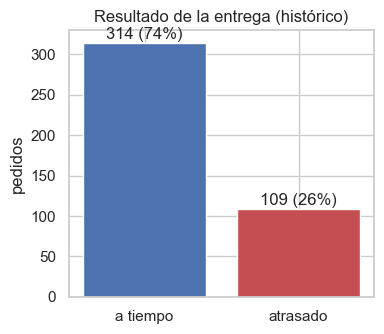

In [6]:
conteo = historico["atrasado"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(4, 3.5))
ax.bar(["a tiempo", "atrasado"], conteo.values, color=["#4C72B0", "#C44E52"])
for i in range(len(conteo)):
    ax.text(i, conteo.values[i] + 5, f"{conteo.values[i]} ({conteo.values[i] / N_HIST:.0%})", ha="center")
ax.set_ylabel("pedidos")
ax.set_title("Resultado de la entrega (histórico)")
plt.tight_layout()
plt.show()

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿es un problema frecuente o raro? ¿Qué desbalance hay entre las dos clases y qué implica para elegir métricas? ¿Alcanza el cupo para cubrir los atrasos esperados? ¿Conviene mandar todo por premium?_

### 2.2 Calidad de los datos

No hay que hacer limpieza como tal (no llegan los tiempos), pero **sí hay que saber qué hay**: cada rareza obliga a una decisión (la dejo, la acoto, la ignoro) y la tienen que poder justificar.

Ojo con el reflejo que traemos de regresión lineal (Clase 04): ahí un valor extremo distorsiona la recta y se saca. Acá vamos a usar árboles, que cortan por umbrales y no se "rompen" con extremos. Antes de borrar algo hay que preguntarse si es un error de carga o un caso real que forma parte de la señal.

Tres revisiones: nulos, valores extremos y consistencia entre columnas.

In [7]:
nulos = pd.DataFrame({
    "nulos histórico": historico.isna().sum(),
    "% histórico": historico.isna().mean() * 100,
    "nulos casos nuevos": nuevos.isna().sum(),
    "% casos nuevos": nuevos.isna().mean() * 100,
}).round(1)
nulos[(nulos["nulos histórico"] > 0) | (nulos["nulos casos nuevos"] > 0)]

,nulos histórico,% histórico,nulos casos nuevos,% casos nuevos
contactos_atencion,0,0.0,141.0,100.0
courier,9,2.1,8.0,5.7
dias_entrega,0,0.0,141.0,100.0
nps,161,38.1,141.0,100.0
peso_kg,21,5.0,7.0,5.0


,count,mean,std,min,1%,50%,99%,max
peso_kg,402.0,3.4,7.7,0.0,0.3,2.0,20.8,110.0
monto_ars,423.0,73849.4,68800.2,4800.0,11798.0,55800.0,385732.0,544000.0
cant_items,423.0,2.2,1.1,1.0,1.0,2.0,6.0,6.0
dias_prometidos,423.0,4.4,2.0,2.0,2.0,4.0,9.0,9.0
descuento_pct,423.0,9.9,10.3,0.0,0.0,5.0,30.0,30.0


Los 6 paquetes más pesados:


,peso_kg,monto_ars,cant_items,zona,atrasado
114,110.0,53900,2,AMBA,1
406,85.0,83800,3,NEA,0
73,55.0,27900,3,AMBA,0
287,30.0,63900,2,CUY,1
231,20.8,39300,6,AMBA,0
303,16.8,47000,2,AMBA,0


Pedidos con peso igual a 0: 1


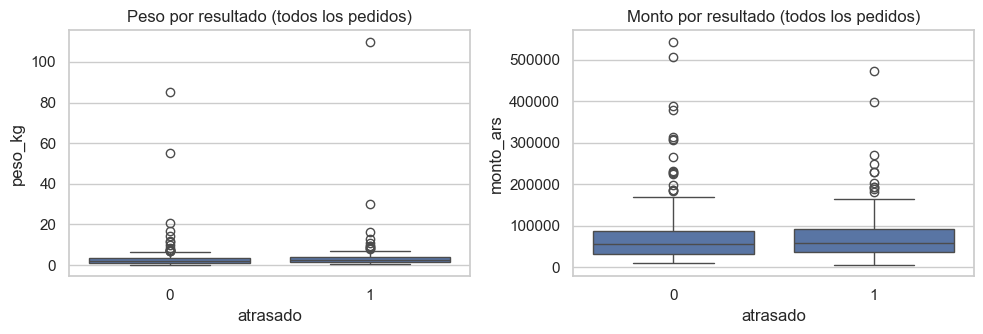

In [8]:
numericas = ["peso_kg", "monto_ars", "cant_items", "dias_prometidos", "descuento_pct"]
display(historico[numericas].describe(percentiles=[0.01, 0.5, 0.99]).T.round(1))

print("Los 6 paquetes más pesados:")
display(historico.nlargest(6, "peso_kg")[["peso_kg", "monto_ars", "cant_items", "zona", "atrasado"]])
print("Pedidos con peso igual a 0:", (historico["peso_kg"] == 0).sum())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.boxplot(data=historico, x="atrasado", y="peso_kg", ax=axes[0])
axes[0].set_title("Peso por resultado (todos los pedidos)")
sns.boxplot(data=historico, x="atrasado", y="monto_ars", ax=axes[1])
axes[1].set_title("Monto por resultado (todos los pedidos)")
plt.tight_layout()
plt.show()

In [9]:
# El metadata dice: atrasado = 1 si llegó después del plazo prometido. ¿Se cumple en los datos?
llego_tarde_segun_dias = (historico["dias_entrega"] > historico["dias_prometidos"]).astype(int)
inconsistentes = historico[llego_tarde_segun_dias != historico["atrasado"]]

print(f"Pedidos donde la etiqueta no coincide con (dias_entrega > dias_prometidos): {len(inconsistentes)} de {N_HIST} ({len(inconsistentes) / N_HIST:.1%})")
display(inconsistentes[["zona", "courier", "dias_prometidos", "dias_entrega", "atrasado"]].head(8))

print("\nPedidos repetidos en el histórico:", historico["pedido_id"].duplicated().sum())
print("Pedidos que están en histórico y en casos nuevos:", len(set(historico["pedido_id"]) & set(nuevos["pedido_id"])))
print("Fechas histórico:", historico["fecha_compra"].min().date(), "a", historico["fecha_compra"].max().date())
print("Fechas casos nuevos:", nuevos["fecha_compra"].min().date(), "a", nuevos["fecha_compra"].max().date())

Pedidos donde la etiqueta no coincide con (dias_entrega > dias_prometidos): 0 de 423 (0.0%)


,zona,courier,dias_prometidos,dias_entrega,atrasado



Pedidos repetidos en el histórico: 0
Pedidos que están en histórico y en casos nuevos: 0
Fechas histórico: 2026-09-07 a 2026-10-25
Fechas casos nuevos: 2026-09-07 a 2026-10-25


**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿qué columnas tienen nulos y en qué proporción? ¿Los extremos de peso son errores de carga o casos posibles? ¿Hay pedidos con valores que no tienen sentido físico? ¿La etiqueta `atrasado` es coherente con `dias_entrega` y `dias_prometidos`, como dice el metadata? Fijense también en las fechas de `casos_nuevos`: ¿es un lote posterior al histórico?_

### 2.3 ¿Los casos nuevos se parecen al histórico?

El modelo aprende del histórico pero **decide sobre `casos_nuevos`**. Si los dos archivos se parecen poco, lo que aprendimos no se traslada. Comparamos la composición del lote y hacemos una cuenta rápida: si cada pedido nuevo se atrasara como el promedio histórico de su zona, ¿cuántos atrasos tendríamos?

In [10]:
for col in ["zona", "courier", "canal", "envio_partido", "dias_prometidos"]:
    comparacion = pd.DataFrame({
        "histórico %": historico[col].value_counts(normalize=True, dropna=False) * 100,
        "nuevos %": nuevos[col].value_counts(normalize=True, dropna=False) * 100,
    }).round(1)
    print(col)
    display(comparacion.sort_index())

zona


,histórico %,nuevos %
zona,,
AMBA,41.1,33.3
CEN,10.9,13.5
CUY,9.9,13.5
LIT,14.4,12.1
NEA,6.4,9.2
NOA,9.9,10.6
PAT,7.3,7.8


courier


,histórico %,nuevos %
courier,,
K1,42.8,36.2
K2,31.2,29.1
K3,23.9,29.1
NaN,2.1,5.7


canal


,histórico %,nuevos %
canal,,
app,51.1,47.5
mkt,14.9,15.6
web,34.0,36.9


envio_partido


,histórico %,nuevos %
envio_partido,,
0,83.5,84.4
1,16.5,15.6


dias_prometidos


,histórico %,nuevos %
dias_prometidos,,
2,23.6,14.9
3,15.4,17.0
4,18.4,14.9
5,13.2,17.7
6,13.5,13.5
7,6.6,11.3
8,6.9,9.2
9,2.4,1.4


In [11]:
columnas = ["peso_kg", "monto_ars", "cant_items", "descuento_pct", "primera_compra"]
display(pd.DataFrame({
    "histórico (media)": historico[columnas].mean(),
    "nuevos (media)": nuevos[columnas].mean(),
    "histórico (mediana)": historico[columnas].median(),
    "nuevos (mediana)": nuevos[columnas].median(),
}).round(2))

tasa_zona = historico.groupby("zona")["atrasado"].mean()
esperados_por_zona = nuevos["zona"].map(tasa_zona).sum()
print(f"\nAtrasos esperados en el lote según la zona de cada pedido: {esperados_por_zona:.0f} de {N_NUEVOS} ({esperados_por_zona / N_NUEVOS:.1%})")
print(f"Atrasos esperados con la tasa histórica global: {atrasos_esperados:.0f}")
print(f"Cupo premium: {CUPO}")

,histórico (media),nuevos (media),histórico (mediana),nuevos (mediana)
peso_kg,3.35,2.46,1.95,1.7
monto_ars,73849.41,69529.08,55800.00,55400.0
cant_items,2.19,2.23,2.00,2.0
descuento_pct,9.92,10.78,5.00,10.0
primera_compra,0.33,0.30,0.00,0.0



Atrasos esperados en el lote según la zona de cada pedido: 38 de 141 (27.2%)
Atrasos esperados con la tasa histórica global: 36
Cupo premium: 25


**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿el lote nuevo tiene la misma mezcla de zonas, couriers y plazos? ¿Esperamos más o menos atrasos que en el histórico? ¿Qué pasa con el cupo frente a esa cantidad esperada?_

### 2.4 Qué se sabe al momento de decidir

La decisión se toma **cuando el pedido está por salir**. Entonces no todas las columnas sirven para predecir: algunas se registran *después* de la entrega.

La tabla mide dos cosas por variable: qué tan bien separa atrasados de no atrasados por sí sola (**AUC individual**: 0.5 es "no separa nada", 1 es "separa perfecto") y qué porcentaje de sus valores **viene cargado en `casos_nuevos`**. Es un ranking exploratorio sobre todo el histórico, no la métrica final de ningún modelo (eso viene en la sección 4).

,variable,auc_individual,% con dato en casos nuevos,en casos nuevos
0,dias_entrega,0.91,0.00,viene vacía
1,zona,0.67,100.00,viene con dato
2,dia_semana,0.64,100.00,viene con dato
3,envio_partido,0.64,100.00,viene con dato
4,courier,0.62,94.33,viene con dato
5,dias_prometidos,0.62,100.00,viene con dato
6,peso_kg,0.57,95.04,viene con dato
7,hora,0.57,100.00,viene con dato
8,cant_items,0.54,100.00,viene con dato
9,primera_compra,0.54,100.00,viene con dato


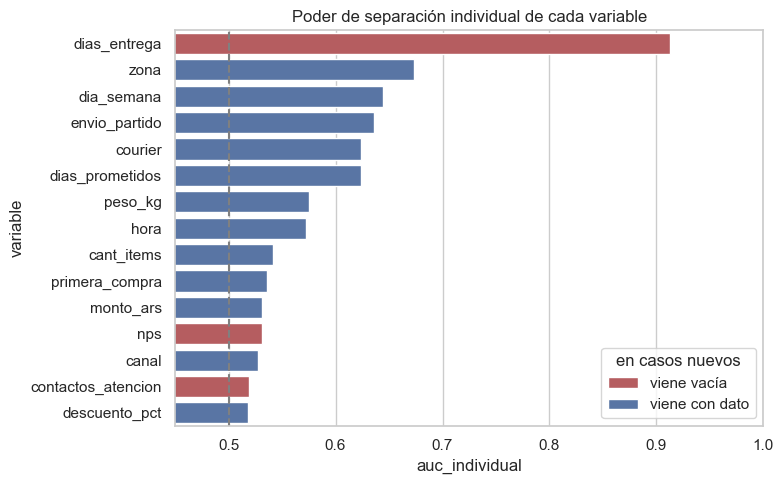

In [12]:
VARIABLES = [
    "zona", "peso_kg", "monto_ars", "cant_items", "courier", "dias_prometidos", "envio_partido",
    "canal", "primera_compra", "descuento_pct", "hora", "dia_semana",
    "dias_entrega", "nps", "contactos_atencion",
]

filas = []
for col in VARIABLES:
    filas.append({
        "variable": col,
        "auc_individual": auc_individual(historico, col, "atrasado"),
        "% con dato en casos nuevos": nuevos[col].notna().mean() * 100,
    })
poder = pd.DataFrame(filas).sort_values("auc_individual", ascending=False).reset_index(drop=True)
poder["en casos nuevos"] = np.where(poder["% con dato en casos nuevos"] > 0, "viene con dato", "viene vacía")
display(poder.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
colores = {"viene con dato": "#4C72B0", "viene vacía": "#C44E52"}
sns.barplot(data=poder, y="variable", x="auc_individual", hue="en casos nuevos", palette=colores, dodge=False, ax=ax)
ax.axvline(0.5, color="gray", linestyle="--")
ax.set_xlim(0.45, 1)
ax.set_title("Poder de separación individual de cada variable")
plt.tight_layout()
plt.show()

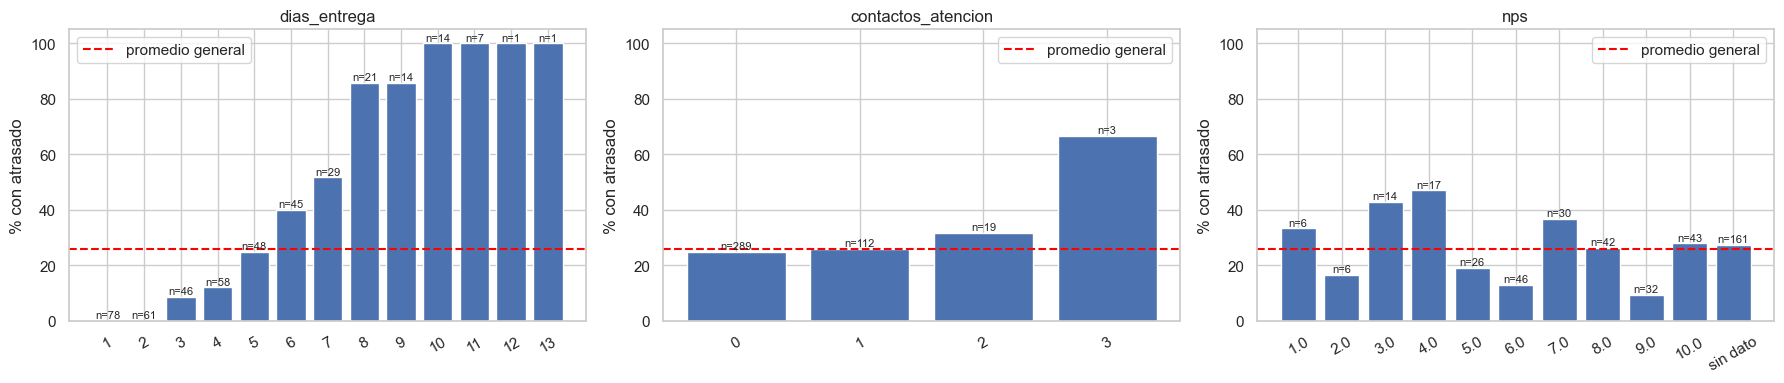

In [13]:
grilla_tasas(historico, ["dias_entrega", "contactos_atencion", "nps"], "atrasado", ancho=6)

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿qué variables encabezan el ranking y están vacías en `casos_nuevos`? ¿Por qué un AUC altísimo no las hace útiles? Si las usáramos igual, ¿qué pasaría el día que hay que decidir con pedidos nuevos? Armen la lista de variables que quedan afuera por este motivo._

### 2.5 Variable por variable: % de atrasados por categoría

Una variable a la vez. Cada barra es el % de pedidos atrasados dentro de esa categoría; el **n** indica cuántos pedidos hay. Primero las variables de negocio más obvias (dónde, quién, cómo), después el resto.

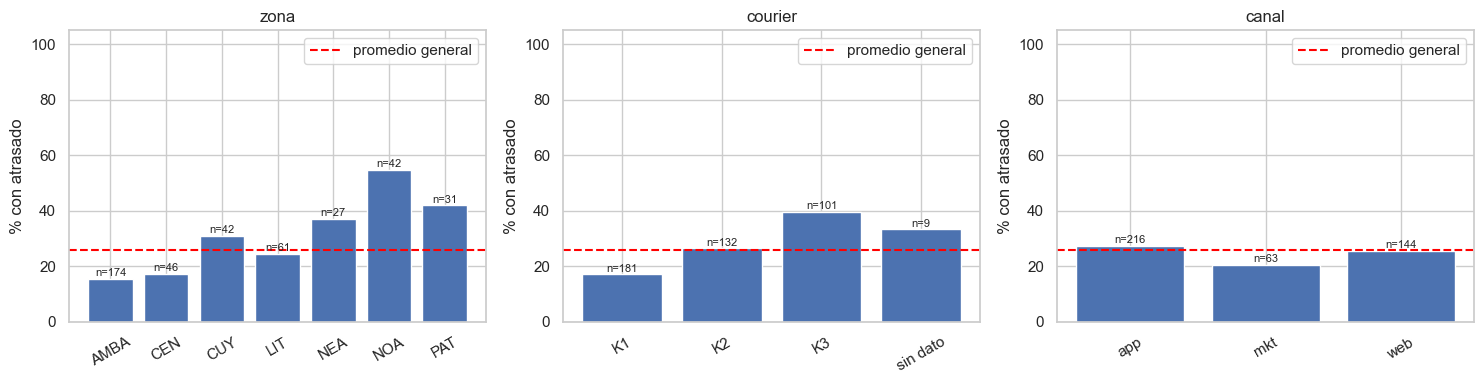

In [14]:
grilla_tasas(historico, ["zona", "courier", "canal"], "atrasado")

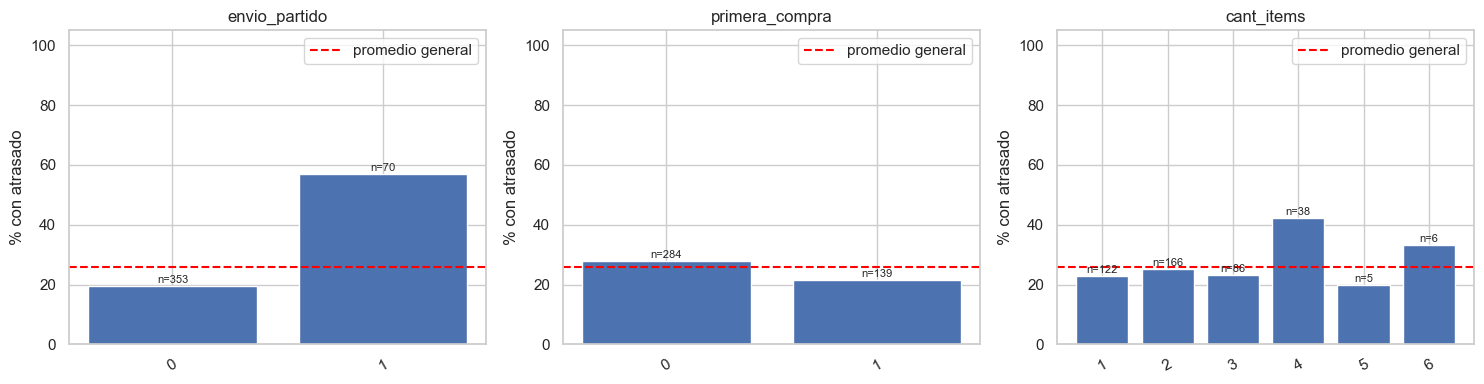

In [15]:
grilla_tasas(historico, ["envio_partido", "primera_compra", "cant_items"], "atrasado")

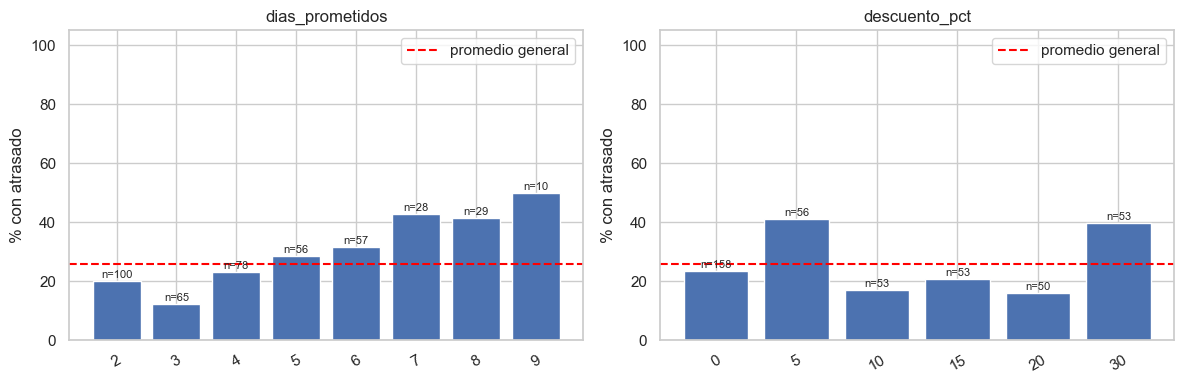

In [16]:
grilla_tasas(historico, ["dias_prometidos", "descuento_pct"], "atrasado", ancho=6)

Además del **porcentaje**, importa dónde está el **volumen**: una zona con tasa altísima pero pocos pedidos aporta pocos atrasos en total. Esta tabla compara qué parte de los pedidos y qué parte de los atrasos aporta cada zona.

In [17]:
pareto = historico.groupby("zona", observed=True)["atrasado"].agg(pedidos="count", atrasos="sum", tasa="mean")
pareto["tasa_%"] = pareto["tasa"] * 100
pareto["% de los pedidos"] = pareto["pedidos"] / pareto["pedidos"].sum() * 100
pareto["% de los atrasos"] = pareto["atrasos"] / pareto["atrasos"].sum() * 100
pareto.drop(columns="tasa").sort_values("% de los atrasos", ascending=False).round(1)

,pedidos,atrasos,tasa_%,% de los pedidos,% de los atrasos
zona,,,,,
AMBA,174,27,15.5,41.1,24.8
NOA,42,23,54.8,9.9,21.1
LIT,61,15,24.6,14.4,13.8
PAT,31,13,41.9,7.3,11.9
CUY,42,13,31.0,9.9,11.9
NEA,27,10,37.0,6.4,9.2
CEN,46,8,17.4,10.9,7.3


**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿qué categorías se despegan claramente del promedio y con qué n? ¿Alguna diferencia podría ser ruido por tener pocos casos? ¿Hay algún resultado que no tenga una explicación de negocio razonable (por ejemplo, el descuento)? ¿Qué variables no parecen mover nada?_

### 2.6 Variables continuas: peso y monto

Peso y monto son continuas y tienen valores extremos (lo vimos en 2.2). Las agrupamos en **quintiles**: cinco grupos con la misma cantidad de pedidos cada uno, de menor a mayor. Así un paquete de 110 kg no distorsiona el gráfico y se compara una cantidad parecida de pedidos en cada barra.

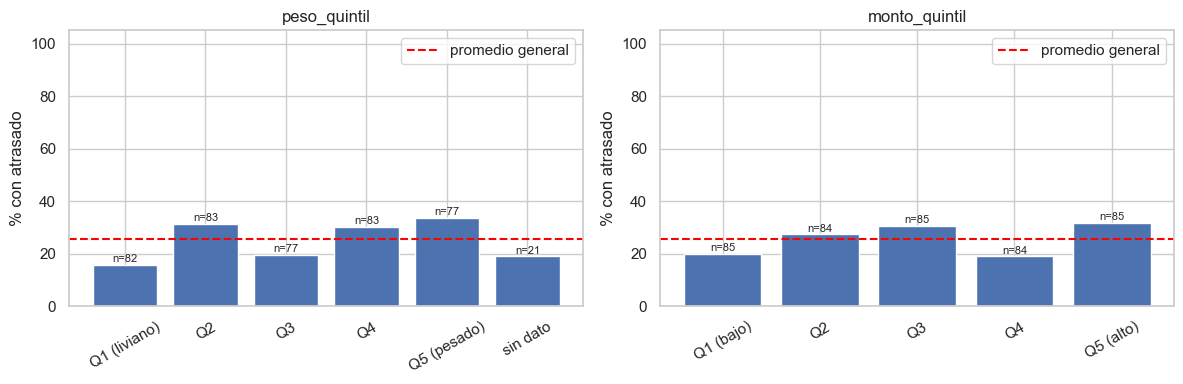

In [18]:
historico["peso_quintil"] = pd.qcut(historico["peso_kg"], 5, labels=["Q1 (liviano)", "Q2", "Q3", "Q4", "Q5 (pesado)"])
historico["monto_quintil"] = pd.qcut(historico["monto_ars"], 5, labels=["Q1 (bajo)", "Q2", "Q3", "Q4", "Q5 (alto)"])

grilla_tasas(historico, ["peso_quintil", "monto_quintil"], "atrasado", ancho=6)

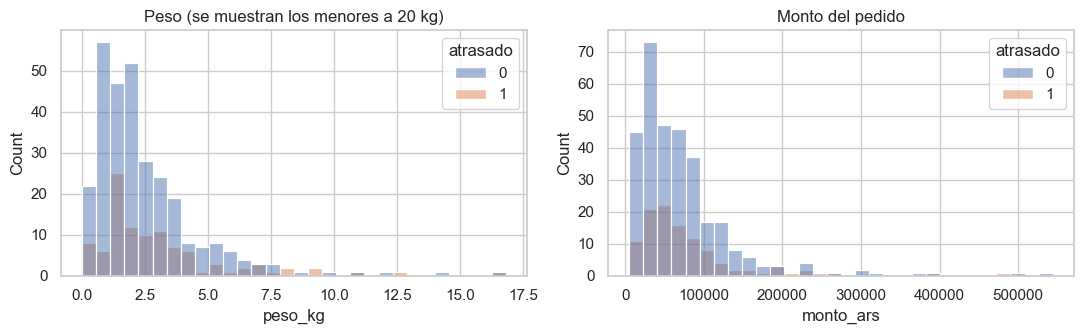

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(data=historico[historico["peso_kg"] < 20], x="peso_kg", hue="atrasado", bins=30, ax=axes[0])
axes[0].set_title("Peso (se muestran los menores a 20 kg)")
sns.histplot(data=historico, x="monto_ars", hue="atrasado", bins=30, ax=axes[1])
axes[1].set_title("Monto del pedido")
plt.tight_layout()
plt.show()

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿el riesgo crece de forma ordenada con el peso o el monto, o las diferencias son chicas y erráticas? ¿Los dos grupos (atrasado / a tiempo) tienen distribuciones distintas?_

### 2.7 Cuándo se compra

El momento de la compra existe antes de despachar, así que es información válida. Probamos el día de la semana, la franja horaria, la combinación de ambos y la evolución semanal (por si el problema empeora o mejora con el tiempo).

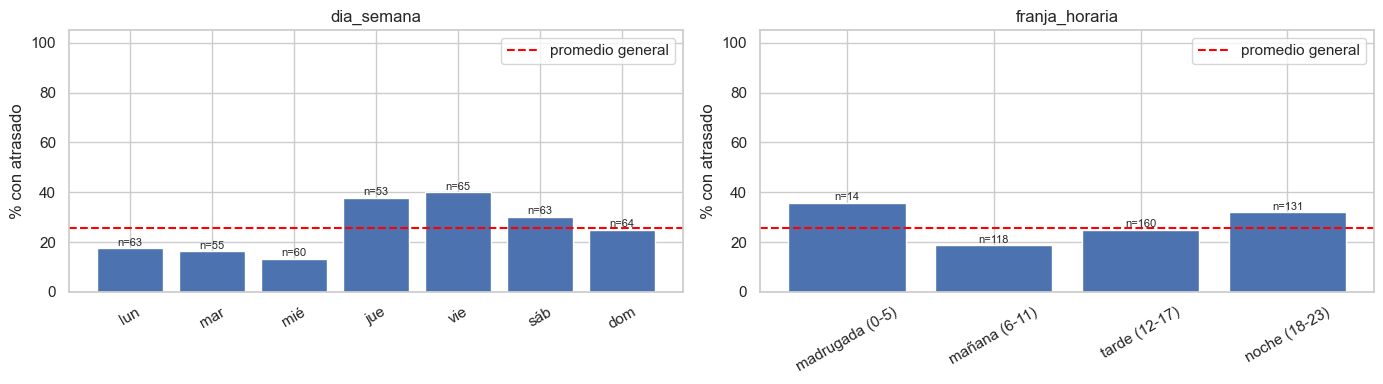

In [20]:
grilla_tasas(historico, ["dia_semana", "franja_horaria"], "atrasado", ancho=7)

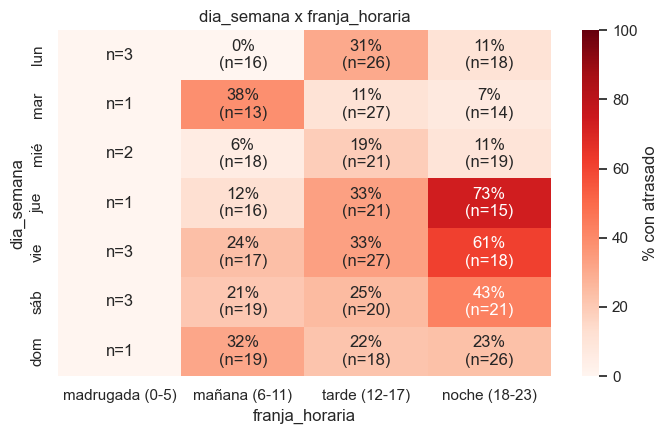

In [21]:
fig, ax = plt.subplots(figsize=(7, 4.5))
mapa_tasa(historico, "dia_semana", "franja_horaria", "atrasado", ax)
plt.tight_layout()
plt.show()

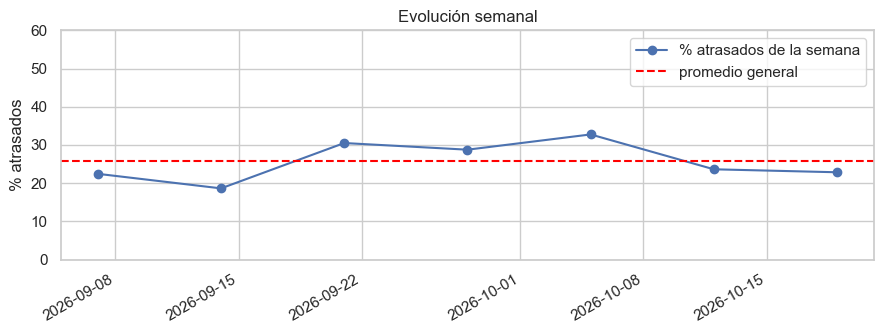

In [22]:
semanal = historico.groupby(historico["fecha_compra"].dt.to_period("W").dt.start_time)["atrasado"].agg(tasa="mean", n="count")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(semanal.index, semanal["tasa"] * 100, marker="o", label="% atrasados de la semana")
ax.axhline(historico["atrasado"].mean() * 100, color="red", linestyle="--", label="promedio general")
ax.set_ylabel("% atrasados")
ax.set_ylim(0, 60)
ax.set_title("Evolución semanal")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿hay días u horarios claramente peores? ¿El mapa de calor muestra una combinación puntual (día + franja) que concentre el riesgo? ¿Qué explicación de negocio le encuentran (piensen en cuándo sale el courier y qué pasa con el fin de semana)? ¿Hay una tendencia a lo largo de las semanas?_

### 2.8 Combinaciones de variables

Los efectos suelen aparecer **combinados**: una variable pesa o no según el valor de otra. Los mapas de calor muestran el % de atrasados por cruce. Las celdas con menos de 5 pedidos se dejan sin color (solo se muestra el n), para no sacar conclusiones de muestras diminutas.

Esto además anticipa por qué vamos a usar modelos de árboles: capturan interacciones solos, sin que nosotros las armemos a mano (en regresión lineal sí había que crearlas).

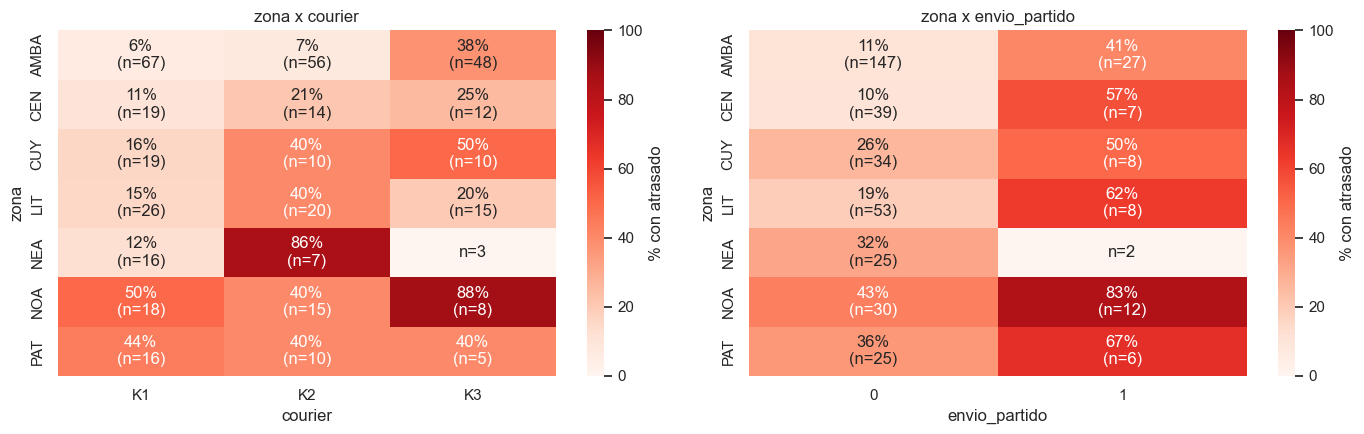

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
mapa_tasa(historico, "zona", "courier", "atrasado", axes[0])
mapa_tasa(historico, "zona", "envio_partido", "atrasado", axes[1])
plt.tight_layout()
plt.show()

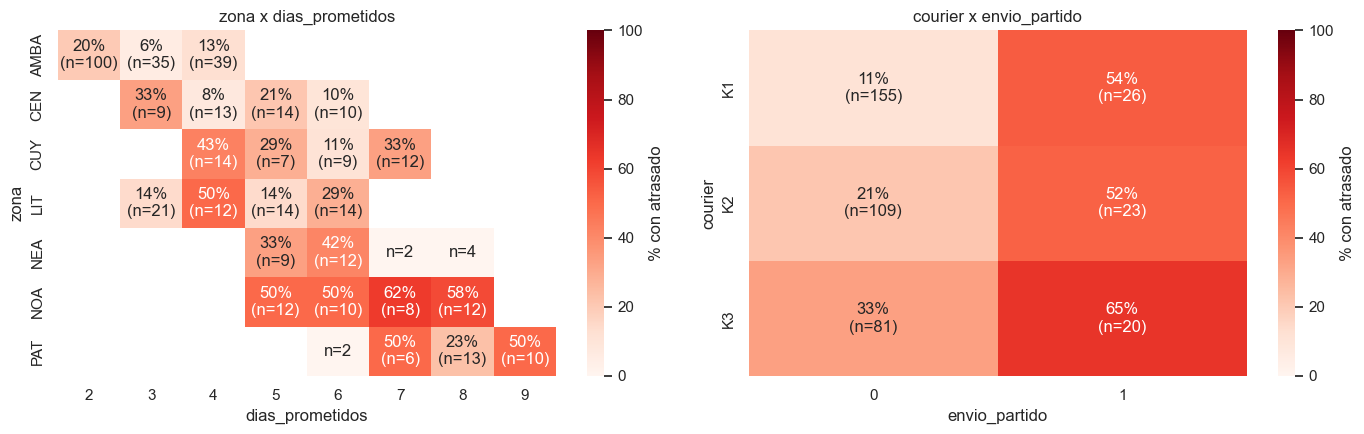

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
mapa_tasa(historico, "zona", "dias_prometidos", "atrasado", axes[0])
mapa_tasa(historico, "courier", "envio_partido", "atrasado", axes[1])
plt.tight_layout()
plt.show()

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿algún courier se comporta distinto según la zona? ¿El envío partido empeora todo por igual o más en algunos lugares? El plazo prometido, ¿explica el atraso por sí solo o es la zona la que manda? ¿Qué combinaciones son un riesgo alto con n suficiente?_

### 2.9 Correlaciones

Resumen rápido de la relación lineal de cada variable numérica con el atraso. Es útil como panorama, pero tiene un límite: la correlación solo detecta relaciones que van "siempre para el mismo lado". Comparenlo con lo que ya vieron en los gráficos de 2.5 a 2.8.

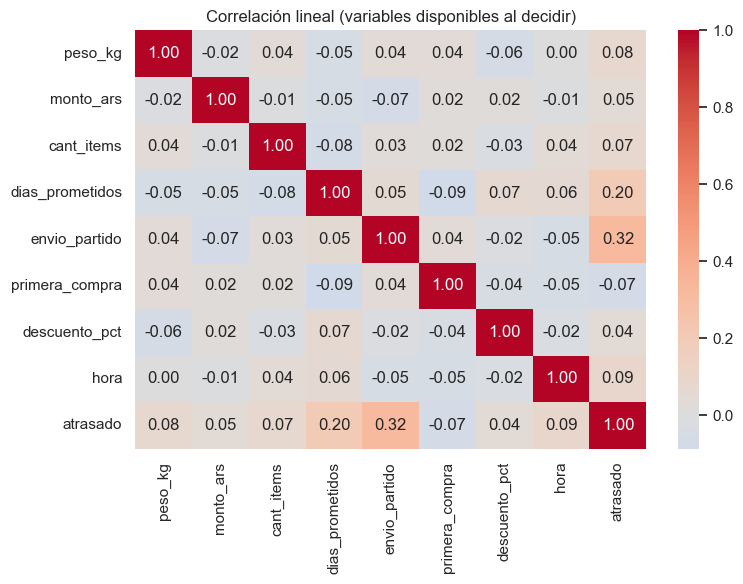

In [25]:
numericas = ["peso_kg", "monto_ars", "cant_items", "dias_prometidos", "envio_partido",
             "primera_compra", "descuento_pct", "hora", "atrasado"]

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(historico[numericas].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlación lineal (variables disponibles al decidir)")
plt.tight_layout()
plt.show()

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿qué variables tienen correlación visible con `atrasado`? ¿Hay patrones fuertes en los gráficos anteriores que acá NO aparecen? ¿Por qué?_

### 2.10 Dónde se concentra el problema

Para decidir a quién le asignamos premium nos sirve conocer los segmentos de **riesgo alto con volumen suficiente**. Esta tabla cruza zona y courier (solo grupos de 10 pedidos o más) y muestra cuántos atrasos aporta cada uno al total.

In [26]:
segmentos = historico.groupby(["zona", "courier"], observed=True)["atrasado"].agg(pedidos="count", atrasos="sum", tasa="mean")
segmentos["tasa_%"] = segmentos["tasa"] * 100
segmentos["% del total de atrasos"] = segmentos["atrasos"] / historico["atrasado"].sum() * 100
segmentos = segmentos[segmentos["pedidos"] >= 10].drop(columns="tasa")

print("Mayor tasa de atraso:")
display(segmentos.sort_values("tasa_%", ascending=False).head(8).round(1))
print("Mayor aporte al total de atrasos:")
display(segmentos.sort_values("atrasos", ascending=False).head(8).round(1))

Mayor tasa de atraso:


,,pedidos,atrasos,tasa_%,% del total de atrasos
zona,courier,,,,
CUY,K3,10,5,50.0,4.6
NOA,K1,18,9,50.0,8.3
PAT,K1,16,7,43.8,6.4
NOA,K2,15,6,40.0,5.5
CUY,K2,10,4,40.0,3.7
PAT,K2,10,4,40.0,3.7
LIT,K2,20,8,40.0,7.3
AMBA,K3,48,18,37.5,16.5


Mayor aporte al total de atrasos:


,,pedidos,atrasos,tasa_%,% del total de atrasos
zona,courier,,,,
AMBA,K3,48,18,37.5,16.5
NOA,K1,18,9,50.0,8.3
LIT,K2,20,8,40.0,7.3
PAT,K1,16,7,43.8,6.4
NOA,K2,15,6,40.0,5.5
CUY,K3,10,5,50.0,4.6
AMBA,K1,67,4,6.0,3.7
CUY,K2,10,4,40.0,3.7


**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿los segmentos de mayor tasa son los mismos que más atrasos aportan? Si el cupo es de 25 pedidos, ¿conviene priorizar por tasa de riesgo, por volumen, o por la probabilidad individual de cada pedido?_

### 2.11 ¿Qué diferencias son reales? Intervalos de confianza

En 2.5 vimos barras con su n, pero un porcentaje calculado sobre 30 casos es mucho más incierto que uno calculado sobre 300. Acá cada punto es la tasa observada y la línea es el **intervalo de confianza del 95%**: el rango donde probablemente está la tasa verdadera.

Regla práctica: si el intervalo de un grupo **no toca** la línea roja del promedio general, la diferencia probablemente no es casualidad. Si la toca, o se superpone con el de otros grupos, cuidado con sacar conclusiones.

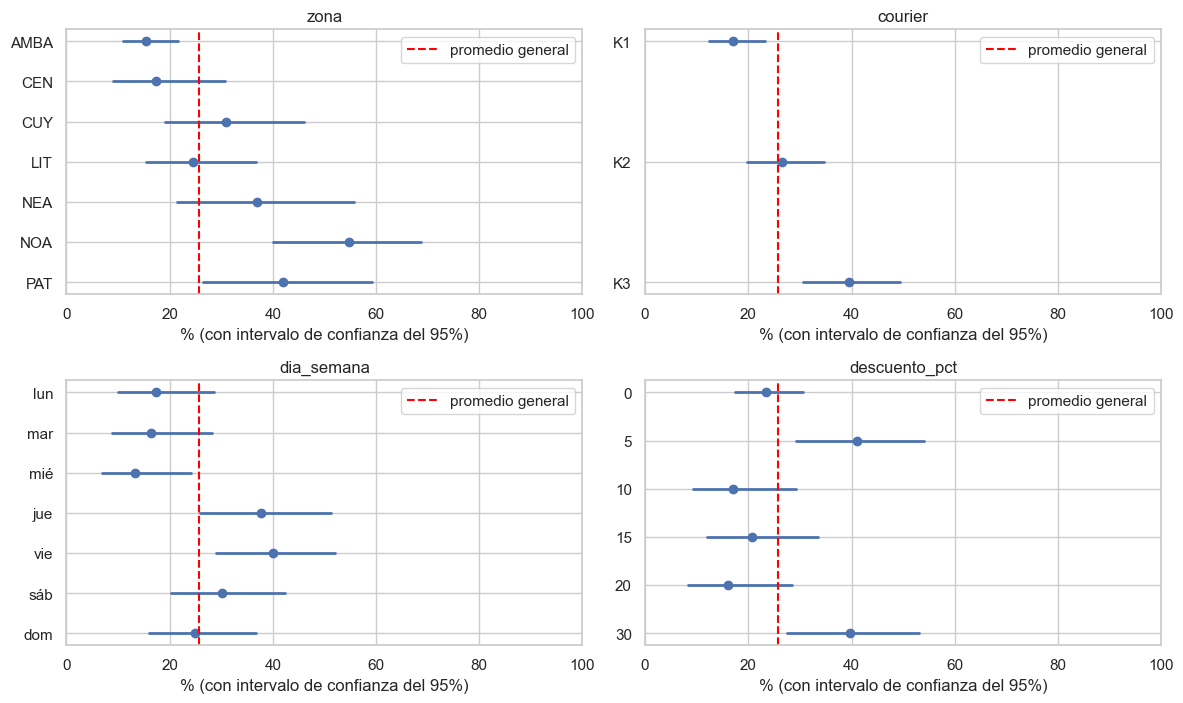

In [27]:
grilla_intervalos(historico, ["zona", "courier", "dia_semana", "descuento_pct"], "atrasado")

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿qué diferencias de 2.5 aguantan el intervalo y cuáles se desarman? ¿Qué categorías tienen un intervalo tan ancho que no se puede decir nada? ¿Qué pasa con el descuento: la barra de 2.5 se veía llamativa, ¿se sostiene?_

### 2.12 Curvas de riesgo para variables continuas

Las variables continuas se leen mejor como **curva** que como barras. Dividimos los casos en 8 grupos de igual tamaño, ubicamos cada grupo en su mediana y marcamos el intervalo de confianza.

Sirve para distinguir si la relación es creciente, decreciente, escalonada o inexistente, y para ver si hay un **punto de quiebre**. Esos puntos son justamente donde un árbol decide cortar.

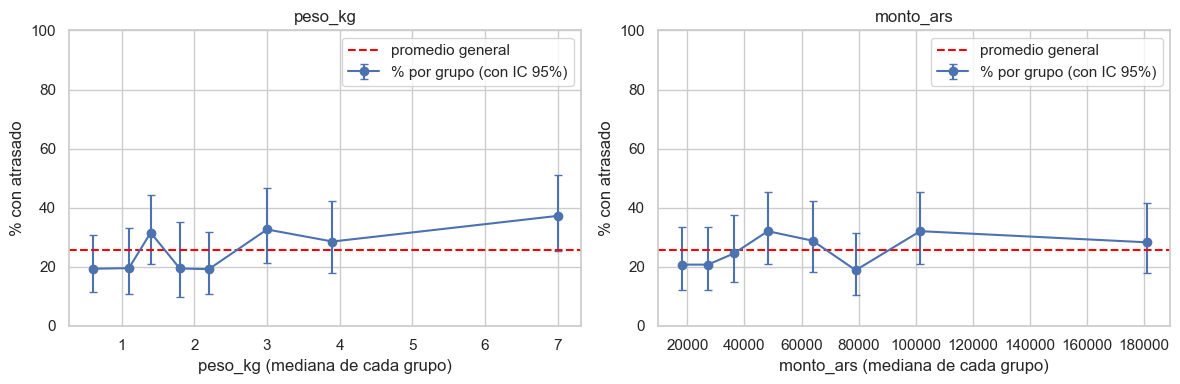

In [28]:
grilla_curvas(historico, ["peso_kg", "monto_ars"], "atrasado")

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿la curva sube, baja, se mueve a escalones o es plana? ¿Hay un punto donde el riesgo cambia de nivel? ¿Los intervalos dejan afirmar que hay una tendencia?_

### 2.13 Volumen contra riesgo

Dos formas de ver dónde está la plata. El **gráfico de burbujas** ubica cada segmento según su cantidad de casos (eje horizontal) y su tasa de riesgo (eje vertical); el tamaño de la burbuja es cuántos casos positivos aporta. El **gráfico de barras** compara qué parte de los casos y qué parte de los positivos aporta cada grupo.

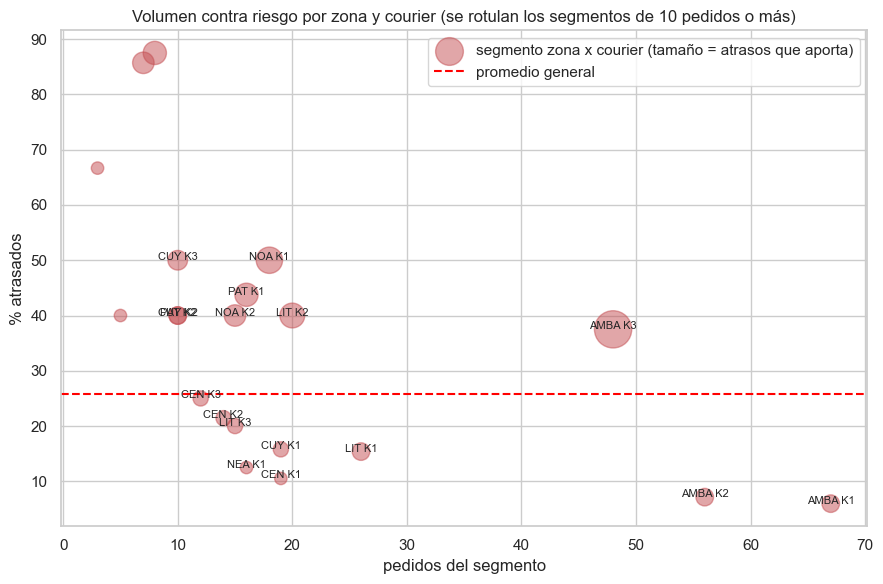

In [29]:
seg = historico.groupby(["zona", "courier"], observed=True)["atrasado"].agg(pedidos="count", atrasos="sum", tasa="mean").reset_index()
seg["segmento"] = seg["zona"].astype(str) + " " + seg["courier"].astype(str)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(seg["pedidos"], seg["tasa"] * 100, s=seg["atrasos"] * 40, alpha=0.5, color="#C44E52",
           label="segmento zona x courier (tamaño = atrasos que aporta)")
for i in range(len(seg)):
    if seg["pedidos"].iloc[i] >= 10:
        ax.annotate(seg["segmento"].iloc[i], (seg["pedidos"].iloc[i], seg["tasa"].iloc[i] * 100), fontsize=8, ha="center")
ax.axhline(historico["atrasado"].mean() * 100, color="red", linestyle="--", label="promedio general")
ax.set_xlabel("pedidos del segmento")
ax.set_ylabel("% atrasados")
ax.set_title("Volumen contra riesgo por zona y courier (se rotulan los segmentos de 10 pedidos o más)")
ax.legend()
plt.tight_layout()
plt.show()

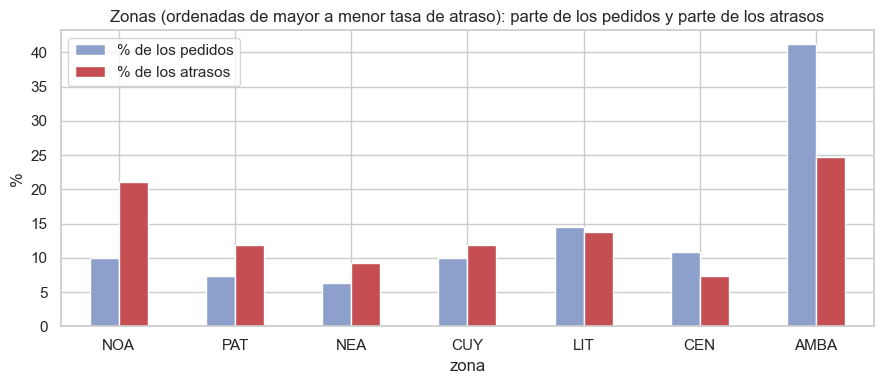

In [30]:
fig, ax = plt.subplots(figsize=(9, 4))
barras = pareto.sort_values("tasa_%", ascending=False)[["% de los pedidos", "% de los atrasos"]]
barras.plot(kind="bar", ax=ax, color=["#8DA0CB", "#C44E52"])
ax.set_ylabel("%")
ax.set_title("Zonas (ordenadas de mayor a menor tasa de atraso): parte de los pedidos y parte de los atrasos")
ax.tick_params(axis="x", labelrotation=0)
ax.legend()
plt.tight_layout()
plt.show()

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿qué segmentos están arriba y a la derecha (riesgo alto y mucho volumen)? ¿Hay segmentos de riesgo altísimo pero tan chicos que mueven poco la plata? ¿Qué grupos aportan más positivos de los que les corresponderían por su tamaño?_

### 2.14 Qué ve un árbol chico

Para pasar del "hay patrones" al "estas son las reglas", entrenamos un **árbol de decisión de profundidad 3** con las variables disponibles al decidir, **solo para leerlo**. No es el modelo del desafío (eso es la sección 4).

Cada caja muestra la regla de corte, cuántos casos caen ahí (`samples`), cuántos son de cada clase (`value`, en el orden [a tiempo, atrasado]) y la clase mayoritaria. El color indica la clase mayoritaria (naranja una, azul la otra) y cuanto más intenso, más "puro" es el grupo. Si la condición de la caja se cumple, el camino va por la izquierda (`True`). Como las variables categóricas se abren en variables 0/1, una caja que dice `zona_NOA <= 0.5` separa lo que **no** cumple esa condición (izquierda) de lo que sí (derecha). `dia_semana_n` va de 0 (lunes) a 6 (domingo).

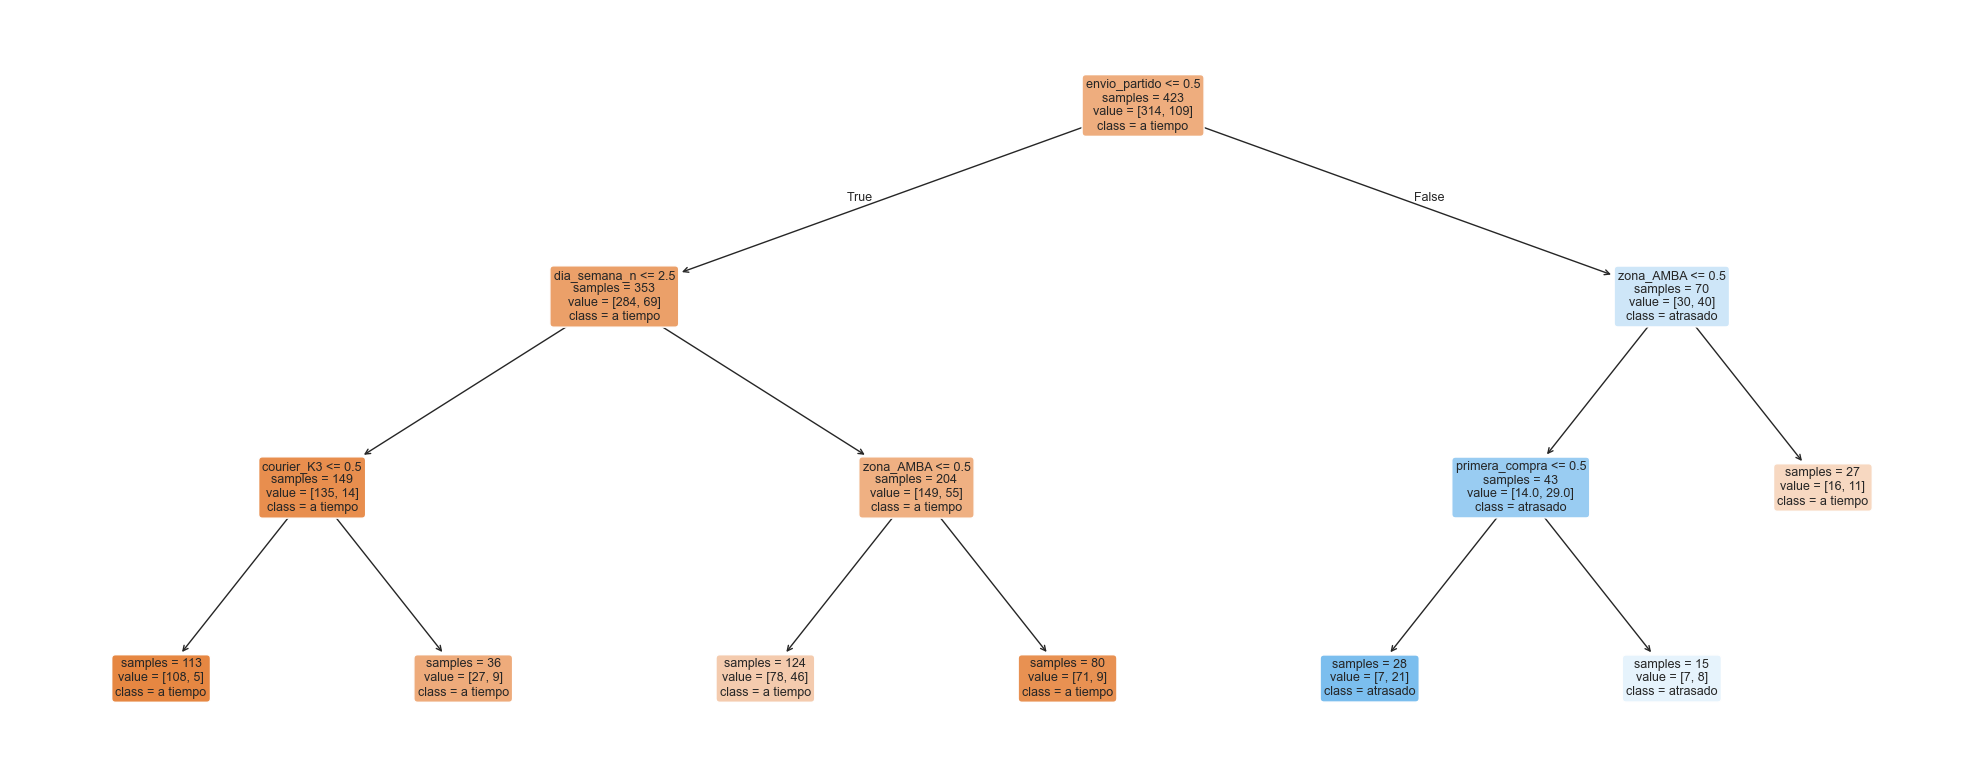

In [31]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

VARIABLES_ARBOL = ["zona", "courier", "canal", "envio_partido", "primera_compra", "descuento_pct", "cant_items", "dias_prometidos", "peso_kg", "monto_ars", "hora"]
CATEGORICAS = ["zona", "courier", "canal"]

X = historico[VARIABLES_ARBOL].copy()
X["dia_semana_n"] = historico["fecha_compra"].dt.dayofweek  # 0 = lunes, 6 = domingo
X = pd.get_dummies(X, columns=CATEGORICAS, dtype=float).fillna(-1)  # -1 marca el dato faltante, solo para esta exploración
y = historico["atrasado"]

arbol = DecisionTreeClassifier(max_depth=3, min_samples_leaf=15, random_state=SEED)
arbol.fit(X, y)

fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(arbol, feature_names=list(X.columns), class_names=["a tiempo", "atrasado"],
          filled=True, impurity=False, rounded=True, fontsize=9, ax=ax)
plt.tight_layout()
plt.show()

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿qué variable usa el árbol para la primera pregunta y coincide con lo que encontraron? ¿Qué hoja concentra más riesgo y qué historia de negocio cuenta? ¿Aparece alguna variable que habían descartado en el EDA?_

### 2.15 ¿Cuánto vale priorizar bien?

Último paso: medir cuánto aporta una regla de priorización respecto de no hacer nada.

La **curva de captura** ordena los casos de mayor a menor riesgo y muestra qué porcentaje de los positivos se captura al ir cubriendo cada vez más casos. Se compara con el azar (la diagonal) y con el orden perfecto (el techo). Las probabilidades salen de un árbol chico evaluado con **validación cruzada**, para no premiarlo por casos que ya vio.

AUC de la regla simple (validación cruzada de 5 folds): 0.67


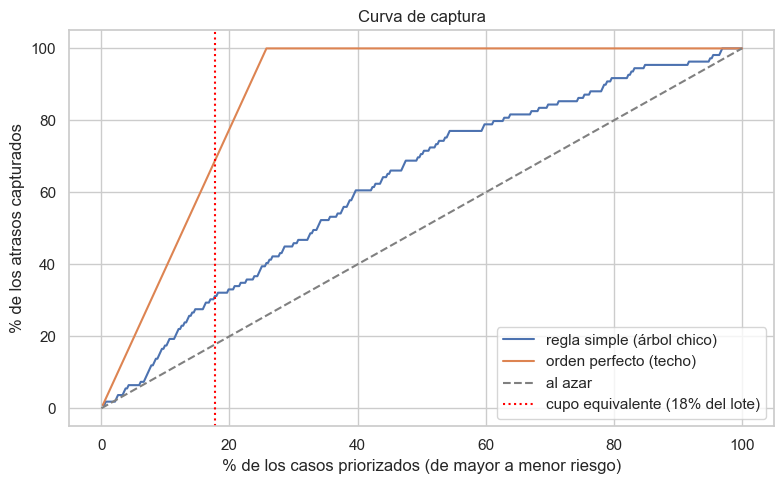

Priorizando el 18% de los casos, la regla captura el 31% de los atrasos (al azar capturaría el 18%).


In [32]:
from matplotlib.ticker import FuncFormatter
from sklearn.model_selection import StratifiedKFold, cross_val_predict


def orden_por_puntaje(puntaje):
    # ordena de mayor a menor puntaje; los empates se desempatan al azar (con semilla fija)
    ruido = np.random.default_rng(SEED).uniform(0, 1e-6, len(puntaje))
    return np.argsort(-(puntaje + ruido))


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
arbol_chico = DecisionTreeClassifier(max_depth=3, min_samples_leaf=15, random_state=SEED)
prob = cross_val_predict(arbol_chico, X, y, cv=cv, method="predict_proba")[:, 1]
print(f"AUC de la regla simple (validación cruzada de 5 folds): {roc_auc_score(y, prob):.2f}")

y_np = y.to_numpy()
total_pos = y_np.sum()
n_casos = len(y_np)
x = np.arange(1, n_casos + 1) / n_casos * 100
capturados = np.cumsum(y_np[orden_por_puntaje(prob)]) / total_pos * 100
techo = np.minimum(np.arange(1, n_casos + 1), total_pos) / total_pos * 100
pct_cupo = CUPO / N_NUEVOS * 100

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, capturados, label="regla simple (árbol chico)")
ax.plot(x, techo, label="orden perfecto (techo)")
ax.plot([0, 100], [0, 100], linestyle="--", color="gray", label="al azar")
ax.axvline(pct_cupo, color="red", linestyle=":", label=f"cupo equivalente ({pct_cupo:.0f}% del lote)")
ax.set_xlabel("% de los casos priorizados (de mayor a menor riesgo)")
ax.set_ylabel("% de los atrasos capturados")
ax.set_title("Curva de captura")
ax.legend()
plt.tight_layout()
plt.show()

captura_en_cupo = np.interp(pct_cupo, x, capturados)
print(f"Priorizando el {pct_cupo:.0f}% de los casos, la regla captura el {captura_en_cupo:.0f}% de los atrasos (al azar capturaría el {pct_cupo:.0f}%).")

Ahora lo traducimos a plata. Comparamos el costo esperado de un lote bajo distintas reglas, siempre respetando el cupo salvo en la barra que dice "ignorando":

Supuesto: un pedido que va por premium llega a tiempo seguro y cuesta $2.700 más que el estándar; un pedido atrasado sin premium cuesta $9.000. El costo se expresa **por lote nuevo** (141 pedidos).

Esto es una **vara a superar**, no la solución. Acá el ordenamiento sale de un árbol de profundidad 3 y no hay un umbral. Qué tan lejos se puede llegar con Random Forest y XGBoost, y cómo se convierte la probabilidad en decisión, es el trabajo de las secciones 4 y 5.

,costo por lote,ahorro vs no hacer nada
"Orden perfecto, hasta el cupo (techo)",$169.500,$157.500
"Una sola variable (zona), hasta el cupo",$280.500,$46.500
"Árbol chico, hasta el cupo",$292.500,$34.500
No hacer nada,$327.000,$0
"Al azar, hasta el cupo",$336.521,$-9.521
Premium a todos (ignorando el cupo),$380.700,$-53.700


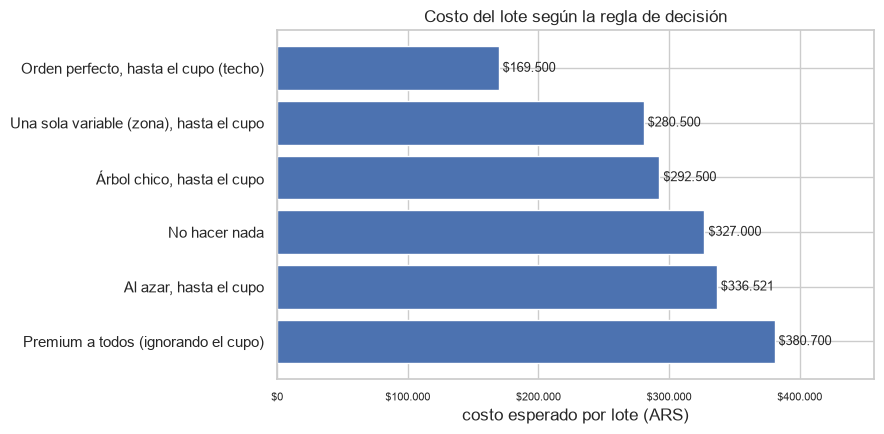

In [33]:
COSTO_ACCION = COSTO_PREMIUM    # lo que cuesta actuar sobre un caso
COSTO_PERDIDA = COSTO_ATRASO   # lo que cuesta un caso positivo que no cubrimos
escala = N_NUEVOS / N_HIST           # para expresar todo por lote nuevo
K = round(CUPO / N_NUEVOS * N_HIST)  # cupo equivalente en el tamaño del histórico


def costo_total(elegidos):
    cubiertos = y_np[elegidos].sum()
    return (len(elegidos) * COSTO_ACCION + (total_pos - cubiertos) * COSTO_PERDIDA) * escala


puntaje_regla = historico["zona"].map(historico.groupby("zona")["atrasado"].mean()).to_numpy()
orden_regla = orden_por_puntaje(puntaje_regla)
orden_arbol = orden_por_puntaje(prob)
orden_techo = np.argsort(-y_np, kind="stable")

costos = {
    "No hacer nada": total_pos * COSTO_PERDIDA * escala,
    "Premium a todos (ignorando el cupo)": costo_total(np.arange(n_casos)),
    "Al azar, hasta el cupo": (K * COSTO_ACCION + (total_pos - K * y_np.mean()) * COSTO_PERDIDA) * escala,
    "Una sola variable (zona), hasta el cupo": costo_total(orden_regla[:K]),
    "Árbol chico, hasta el cupo": costo_total(orden_arbol[:K]),
    "Orden perfecto, hasta el cupo (techo)": costo_total(orden_techo[:K]),
}
tabla = pd.DataFrame({"costo por lote": pd.Series(costos)}).sort_values("costo por lote")
tabla["ahorro vs no hacer nada"] = costos["No hacer nada"] - tabla["costo por lote"]

mostrar = tabla.copy()
for col in mostrar.columns:
    mostrar[col] = mostrar[col].apply(pesos)
display(mostrar)

def formato_pesos(valor, posicion):
    return pesos(valor)


fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(tabla.index, tabla["costo por lote"], color="#4C72B0")
ax.xaxis.set_major_formatter(FuncFormatter(formato_pesos))
ax.tick_params(axis="x", labelsize=8)
for i in range(len(tabla)):
    ax.text(tabla["costo por lote"].iloc[i], i, " " + pesos(tabla["costo por lote"].iloc[i]), va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, tabla["costo por lote"].max() * 1.2)
ax.set_xlabel("costo esperado por lote (ARS)")
ax.set_title("Costo del lote según la regla de decisión")
plt.tight_layout()
plt.show()

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿Alguna regla cuesta más que no hacer nada? Si el premium cuesta la mitad que un atraso, ¿qué tan acertados tenemos que ser con los pedidos que elegimos para no perder plata? ¿Cuánto separa a las reglas simples del techo y qué creen que explica esa distancia? ¿Tiene sentido ignorar el cupo mandando todo por premium?_

### 2.16 Síntesis del EDA

Cierren el EDA con lo que van a llevar a las slides. Mínimo **2 insights**, cada uno con las tres partes, y **uno que no esperaban**.

**Insight 1**
- Qué encontramos: _..._
- Evidencia (número): _..._
- Qué implica para la decisión: _..._

**Insight 2**
- Qué encontramos: _..._
- Evidencia (número): _..._
- Qué implica para la decisión: _..._

**Insight inesperado**
- Qué encontramos: _..._
- Evidencia (número): _..._
- Qué implica para la decisión: _..._

**Variables que usamos en el modelo** (y por qué): _..._

**Variables que descartamos** (y por qué: no están disponibles al decidir, son identificadores, no aportan señal, etc.): _..._

## 3. Preparación

**Stream B.** No hay limpieza de datos como tal (no llegan los tiempos), pero sí hay que dejar el dataset listo para los modelos.

- ¿Qué columnas categóricas hay que convertir a números? ¿Cómo?
- ¿Hay valores nulos en las variables que elegimos? ¿Qué hacemos con ellos?
- ¿Necesitamos escalar las variables? Pensá en lo que vimos con KNN (Clase 05) y comparalo con modelos de árboles.

In [34]:
# Separar X (variables elegidas) e y (target)


In [35]:
# Codificar categóricas


### Partición train / validación

Necesitamos una parte de los datos que el modelo **no vea** para evaluarlo con honestidad.

- ¿Qué proporción reservamos?
- ¿Hace falta `stratify`? Pensá en el porcentaje de positivos de `late_flag` que calcularon en 2.1.

In [36]:
# train_test_split


In [37]:
# Chequear que la proporción del target se mantenga en ambos sets


## 4. Modelado

Se pide entrenar **dos modelos** (Random Forest y XGBoost), cada uno con GridSearch, y compararlos con las mismas reglas.

### 4.1 Elegir la métrica de evaluación

Antes de correr el GridSearch hay que decidir con qué métrica se elige el mejor modelo.

- ¿Sirve `accuracy` si los positivos son pocos? ¿Por qué?
- ¿Qué error es más caro para el negocio: marcar de más o dejar pasar un caso?
- ¿Qué métrica elegimos para `scoring` y por qué?

**Decisión:** _(métrica elegida y justificación de negocio)_

### 4.2 Random Forest + GridSearch

- ¿Qué hiperparámetros vamos a probar? ¿Por qué esos y no otros?
- ¿Cuántos folds de cross validation? ¿Cuántas combinaciones se evalúan en total, y cuánto tarda?

In [38]:
# Definir grilla y correr GridSearchCV para Random Forest


In [39]:
# Mejores hiperparámetros y mejor score en CV


### 4.3 XGBoost + GridSearch

Misma lógica que 4.2, con los hiperparámetros propios de XGBoost.

- ¿Qué cambia respecto del Random Forest en cómo construye los árboles? (Clase 08)

In [40]:
# Definir grilla y correr GridSearchCV para XGBoost


In [41]:
# Mejores hiperparámetros y mejor score en CV


### 4.4 Comparación

Los dos modelos se evalúan **sobre el set de validación**, con las mismas métricas.

- Reportar para cada uno: matriz de confusión, precision, recall, F1 y AUC.
- Curva ROC o Precision-Recall de los dos en un mismo gráfico.

In [42]:
# Métricas de Random Forest en validación


In [43]:
# Métricas de XGBoost en validación


In [44]:
# Tabla comparativa y curvas


**Modelo elegido:** _(cuál y por qué; si la diferencia es chica, ¿vale la pena la complejidad extra?)_

**Importancia de variables:** _(¿coincide con lo que encontramos en el EDA?)_

## 5. Umbral y decisión de negocio

Acá es donde el ejercicio se gana o se pierde. Un modelo con buen AUC no es una decisión: hay que convertir probabilidades en una acción, respetando costos y cupo.

Pensemos con los costos del metadata:

- Si el premium cuesta $2.700 más que el estándar y un atraso cuesta $9.000, ¿a partir de qué probabilidad de atraso conviene mandar un pedido por premium? Hagan la cuenta en el notebook.
- Con ese umbral, ¿cuántos pedidos del lote marcaría el modelo? ¿Entran en el cupo de 25?
- Si no entran, ¿cuáles priorizamos? ¿Qué cambia si ordenamos por probabilidad?
- Si sobran lugares en el cupo, ¿los usamos igual? ¿Por qué sí o por qué no?

In [45]:
# Probabilidades del modelo elegido sobre validación


In [46]:
# Costo total según umbral (curva de costo vs umbral)


In [47]:
# Costo total con la regla top-N por cupo


**Regla de decisión elegida:** _(umbral, top-N o combinación, y justificación en plata)_

**Comparación contra no hacer nada:** _(ahorro estimado por lote)_

## 6. Predicción sobre casos nuevos

Aplicamos el modelo elegido y la regla de decisión sobre `casos_nuevos.csv`.

- ¿Reentrenamos con **todo** el histórico o usamos el modelo ya entrenado? ¿Qué conviene y por qué?
- ¿Cuántos casos marcó el modelo como positivos del total?
- ¿A cuántos van a mandar por premium finalmente, dado el cupo?

In [48]:
# Predecir probabilidades sobre casos_nuevos


In [49]:
# Aplicar la regla de decisión y contar positivos / total


In [50]:
# Lista final de casos elegidos


**Resultado:** _(X positivos sobre Y casos; Z elegidos para mandar por premium)_

**Costo esperado del lote con la regla vs sin hacer nada:** _(estimación)_

## 7. Conclusión y slides

**Stream C.** Entre 2 y 4 slides. Cada una con un título que diga el insight (no el tema), un gráfico y una frase de cierre.

| Slide | Contenido |
|---|---|
| 1 | Insights del EDA (los 2 o 3 más fuertes, con su número) |
| 2 | Modelos: qué se probó, cuál ganó, con qué métricas |
| 3 | Decisión de negocio: regla elegida y cuánta plata mueve |
| 4 (opcional) | Riesgos y límites: qué no sabemos, qué monitorearíamos |

### Para ensayar el pitch (8 minutos + 2 de preguntas)

Presenta alguien al azar. Cualquiera del equipo tiene que poder responder:

- ¿Por qué eligieron esa métrica?
- ¿Por qué ese umbral?
- ¿Qué pasa si el cupo se duplica? ¿Y si cambia el costo del premium?
- ¿Qué variable pesa más en el modelo y tiene sentido para el negocio?
- ¿Qué haría el equipo distinto con una semana más?

**Conclusión de negocio:** _(2 o 3 líneas: qué recomendamos hacer, cuánto se gana y qué hay que vigilar)_